In [1]:
import numpy as np
import pandas as pd
import os
import matplotlib.pyplot as plt
import matplotlib
from pathlib import Path
from matplotlib import rcParams
import plotting_functions

In [2]:
# Define base directories
# Base paths
base_auc = "data_Figs/Fig_AUC_all_subtypes"
base_fix = "data_Figs/Fig_Fix_prob_all_subtypes"
#Load Data
data_3HA = plotting_functions.load_data("H3N2", "HA",base_auc,base_fix)
data_3NA = plotting_functions.load_data("H3N2", "NA",base_auc,base_fix)
data_1HA = plotting_functions.load_data("H1N1", "HA",base_auc,base_fix)
data_1NA = plotting_functions.load_data("H1N1", "NA",base_auc,base_fix)


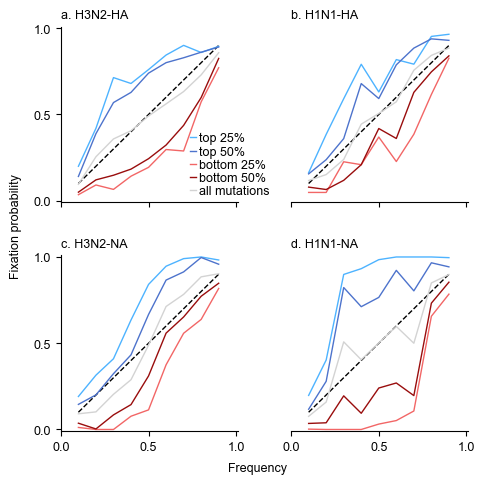

In [12]:
ms = 6
lw = 2

fig, axes = plt.subplots(
    2, 2,
    figsize=plotting_functions.get_figsize("square"),
    sharey=True,
    gridspec_kw={"width_ratios": [1, 1]}
)
axes = axes.flatten()

# Order: top-left, top-right, bottom-left, bottom-right
fix_data = [
    (data_3HA, "a. H3N2-HA"),  # top left
    (data_1HA, "b. H1N1-HA"),  # top right
    (data_3NA, "c. H3N2-NA"),  # bottom left
    (data_1NA, "d. H1N1-NA"),  # bottom right
]

# Plot
for i, (ax, (data, label)) in enumerate(zip(axes, fix_data)):
    plotting_functions.plot_fixation_probability(data, label, ax=ax)

    ax.set_title(label, loc='left')

    # Remove legend from all but first
    if i != 0:
        ax.legend().remove()

    if i % 2 == 1:
        # Right-hand plots: hide y-axis
        ax.set_ylabel("")
        ax.tick_params(axis='y', which='both', left=False, right=False)
        ax.spines['left'].set_visible(False)
    else:
        # Left-hand plots: show y-axis
        ax.tick_params(axis='y', which='both', left=True, right=False)
        ax.spines['left'].set_visible(True)
        # No need to set y-tick labels manually unless customizing

    # Remove x-axis labels for top row
    if i < 2:
        ax.set_xlabel("")
        ax.set_xticks([0.0, 0.5, 1.0])
        ax.set_xticklabels([])  # Hide labels but keep ticks
    else:
        ax.set_xticks([0.0, 0.5, 1.0])

# Adjust spacing
plt.subplots_adjust(wspace=0.3, hspace=0.3)

# Shared axis labels
fig.text(0.5, 0.04, 'Frequency', ha='center', va='center')
fig.text(0.04, 0.5, 'Fixation probability', ha='center', va='center', rotation='vertical')

fig.savefig("Fix_prob_all_proteins_square_layout.pdf", dpi=300, bbox_inches='tight')
plt.show()